# 1. Research Question

### In two Dimentions, how is the intesity of electromagnetic radiation porportional to distance from the emitting source?

# 2. Model and Method

### Equations

Maxwell's equasions in a vacuum are given by $\nabla \times E = -\frac{\partial B}{\partial t}$ and $\nabla \times B = \mu_0 \epsilon_0 \frac{\partial E}{\partial t}$.

Assuming we are in 2 dimentions, ie, that all partials with respect to $z$ are 0, and in terms of spacial derivatives, and where $c^2 = \frac{1}{\mu_0 \epsilon_0}$ we can rewrite this as

\begin{aligned}
\frac{\partial E_x}{\partial t}
&= c^2\left(
\frac{\partial B_z}{\partial y}
\right)\\
\frac{\partial E_y}{\partial t}
&= c^2\left(
-\frac{\partial B_z}{\partial x}
\right)\\
\frac{\partial E_z}{\partial t}
&= c^2\left(
\frac{\partial B_y}{\partial x}
-\frac{\partial B_x}{\partial y}
\right)
\end{aligned}

\begin{aligned}
\frac{\partial B_x}{\partial t}
&=
-\frac{\partial E_z}{\partial y}\\
\frac{\partial B_y}{\partial t}
&= \frac{\partial E_z}{\partial x}\\
\frac{\partial B_z}{\partial t}
&= \frac{\partial E_x}{\partial y}
-\frac{\partial E_y}{\partial x}
\end{aligned}

### Assumptions

1. We assume all partials with respect to $z$ to be zero.
2. We assume we are in a vacuum, so there is no electric currrent.
3. We assume that both feilds are 0 at the boundary of our plane of simulation.

### Solver

To solve the partial differential equations, I first evaluate the special partial derivatives across the veild, then set the derivatives of the feild in accordance to Maxwell's equations. Of note is that before I calculate the spacial derivatives, both fields at the boundaries are set to 0, and after maxwell's equasions are applied, I add a boost to the z component of the electric feilds, to act as our signal generator.

the magnetude of the boost to the electric feild is determined by a 2D gaussian, centered at the middle of the simulation plane, and by $\cos(50 \cdot t)$. The gaussian helps there be minimal high frequency noise (discussed later) and the cosine allows our signal to be sinusoidal, just like electromagnetic radiation in real life.

### Settings

1. The length of the simulation plane is 1 meter by 1 meter.
2. $\mu_0 = \epsilon_0 = 1$
3. The simulation plane has 241 grid elements in each dimention.
4. The simulation has 240 timesteps.
5. The total length that is simulated is 0.5 seconds.
6. The source signal is given by $\frac{\partial E_z}{\partial t} += 100 \cdot e^{-\frac{(r^2)} {(0.03^2)}} \cdot \cos(50 \cdot t)$


# 3. Validation

These three figures each show how a different part of the simulation is behaving, which we can compare to what we would expect.

First, the first figure is a grapgh of the total energy of the system as a function of time. Our occilator that is generating the radiation changes the electric feild by a function of cos(50 * t). Because the energy in the fields is determined by thier square, the energy should be porportional to the $\int cos^2(50 \cdot t) dt = \frac{t}{2} + \frac{\sin(100\cdot t)}{200}$ AS shown in the figure, they are extremely close in value. Calculated from the data in the figure, The average deviation between the Data and the Theoratical is 2.33e-12 J. The average deviation divided the average energy is 1.19e-10.

Second, for electromagnetic radiation in a vacuum, we expect the electric and magnetic fields to be porportional to each other. As we can see in the figure, the electric and magnetic fields match each other almost identically, only having a porportionality constant between them. Calculated from the data in the figure, The average deviation between the Electric Field Strength and the Scaled Magnetic Field Strength is 0.00203 N/C. The average deviation divided the root mean square of the electric field is 0.00118.

Third, for electromagnetic radiation in a vacuum, we expect the electric and magnetic fields to be orthogonal to each other. To test this, I have grapghed the inner product of both. If they are orthogonal, we epexct the inner product to be 0 always, which we see in the figure above. Calculated from the data in the figure, The average deviation between the ⟨E|B⟩ and 0 is 0.0 (NT/C).

As for my tolarances, I choose to evaluate the differential equations over 240 frames, which gave me me a maximum relative diviation of of 0.356% (in the second test). This gives me a reasonable amount of accuracy, while allowing the notebook to run in a reasonable amount of time.

# 4. Key Result

First of all, the fuction I used to fit our intensity is $sinc^2(r) \cdot |r|^A$. The reason I chose this function, is because the individual electric and magnetic signals should follow a sign wave. Because we are squaring them to find the instensity, we square $sinc(r)$. Afterwards, we multiply by a power of $|r|$, to determine how the intensity amplitude is porportional to the radius fromt he emmiter.

Using the best fit parameters, along with the covarience matrix, we find that this signal has an intensity porportional to $sinc^2(r) \cdot |r|^A$, where $A = 1.061 \pm 0.004$. **This tells us that the amplitude of our signal's amplitude is porportional to $r^{-0.939 \pm 0.004}$.**

When I decrease the grids resolution from to 241 to 61, our answer remains similar, but less accurate, with the amplitude now being porportional to $r^{-0.7 \pm 0.2}$

This result make sence, as in a 2d we would expect the intensity of light to follow the inverse law, compared to the inverse square law in 3d, or the constant law in 1D. This is because as the signal radiates outwards, its wavefronts only have 1 "direction" to spread out, vs in 3d, where they have 2. Therefore, if my simulation were pefect, we would expect to find the amplitude of our intensity be porportional to $r^{-1}$, which my result is close to.

# 5. Limitations

1. One major issue with my simualtion is the boundary conditions. Setting the feilds at zero adds lots of reflections, but it is better than the other options that I knew how to easily implement. If I were to continute developping this simulation, I would add better boundary conditions to elimiate refelctions, allowing me to have an easier time gather good, clean signals.

2. Second, Because the special derivatives are being calculated on a discrete, square grid, I beleive the diagonals update slightly slower than the straight lines in my simulation. I belevie that this would make the signals decrease slower on the straight lines, and faster on the diagonals. This is a possible explanation to why my porportionality to $r$ is higher than expected.

# 6. Decisions

### 1. Setting the feilds to 0 at the boundary. 

I choose to set the feilds to 0 at my boundary because this was the easiest method I could find to reduce reflections of the singal off of the boundary. The last time i tried to numerically solve PDEs, I set the coundaries to wrap around on each other, like pac-man. This however would've added lots of other signals, when to answer my question, I just wanted one. One issue with this choice is that I do experience some reflections when the signal hits the boundary. Upon investigation, I found some methods to mitigate this, but they seemed too xcomplicated to pursue for now, as the reflectiuons werent too bad using my current strategy.


### 2. Soft vs hard boundary for the emmiter.

Originally, when creating the source of my radiation, i simply changed the value of a couple cells near the center of my simulation. This mean that there was a hard boundary between the cells whos electric feild component were being changed. This created the evffect of a whole bunch of high frequency noice being present throught the lower frequency signal I wanted to test. Removing this hard boundary for a soft one (generated by a gaussian) completley eliminated this high frequency noise, and left me with a very clean signal to analyse.


### 3. Ignorning near the origin of the signal when determining the porportionality with respect to r.

When fitting my signal to $sinc^2(r) \cdot |r|^A$, near the origin, I rarly found a signal shape that fit this function. Likewise, I removed near the boundary, because it the snapshots that I took to do the fit, the signal was very close, but had not reached the boundary yet, to avoid any refelctions. This trimming allowed me to get the cleanest signal possible, of which we could get the most accurate fit to.

# 7. AI Use

AI was heavily consulted on how to optimize my code, specifically, the use of sparcity in the solve_ivp section. AI was also consulted on how to animate the simualtion. I choose to Use AI on these two components because, while useful, ahving a deep understanding of how the animation works, or how the speedup works is not nessecery to udnerstading the how the simulation works. For these two cases, I could remove both of them, and arrive at the same result, but them being there simply majorly speeds up the simulation, and gave me a very intuitive way of seeing whats going on in the simualtion.

Otherwise, I gatered information about how to solve PDEs from the internet, specifically wikipedia. No other person helped me write any of the code.

# Code

In [1]:
# Run this cell first
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from scipy.sparse import diags, eye, kron
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 60
from scipy.optimize import curve_fit

In [2]:
Lx, Ly = 1.0, 1.0
nx, ny = 241, 241
eps, mu = 1.0, 1.0
t_end = 0.5
n_frames = 240
 
x = np.linspace(0.0, Lx, nx)
y = np.linspace(0.0, Ly, ny)
dx = x[1] - x[0]
dy = y[1] - y[0]
X, Y = np.meshgrid(x[1:-1], y[1:-1])
 
mx, my = nx - 2, ny - 2
 
U0 = np.zeros((6, my, mx))
 
c2 = 1.0 / (eps * mu)

sigma = 0.015
source = np.exp(-((X - 0.5)**2 + (Y - 0.5)**2) / (2 * sigma**2))
 
def derivs(t, u):
    P = np.zeros((6, ny, nx))
    P[:, 1:-1, 1:-1] = u.reshape(6, my, mx)
    P[:, 1:-1, 0] = 0 * P[:, 1:-1, 1]
    P[:, 1:-1, -1] = 0 * P[:, 1:-1, -2]
    P[:, 0, 1:-1] = 0 * P[:, 1, 1:-1]
    P[:, -1, 1:-1] = 0 * P[:, -2, 1:-1]
    Px = (P[:, 1:-1, 2:] - P[:, 1:-1, :-2]) / (2.0 * dx)
    Py = (P[:, 2:, 1:-1] - P[:, :-2, 1:-1]) / (2.0 * dy)
    d = np.empty((6, my, mx))
    d[0] = c2 * Py[5]
    d[1] = -c2 * Px[5]
    d[2] = c2 * (Px[4] - Py[3])
    d[3] = -Py[2]
    d[4] = Px[2]
    d[5] = Py[0] - Px[1]
    #hard boundary
    #d[2, ny//2 - 3: -(ny//2 - 3), nx//2 - 3: -(nx//2 - 3)] += 100 * np.cos(50 * t)
    d[2] += 100 * source * np.cos(50 * t)
    return d.ravel()
 
#figure out what this does
tri_x = diags([1.0, 1.0, 1.0], [-1, 0, 1], shape=(mx, mx))
tri_y = diags([1.0, 1.0, 1.0], [-1, 0, 1], shape=(my, my))
stencil = kron(eye(my), tri_x) + kron(tri_y, eye(mx))
coupling = np.array([
    [0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 0, 1],
    [0, 0, 0, 1, 1, 0],
    [0, 0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0, 0],
    [1, 1, 0, 0, 0, 0],
], dtype=float)
sparsity = kron(coupling, stencil)
 
t_eval = np.linspace(0.0, t_end, n_frames)
 
sol = solve_ivp(derivs, (0.0, t_end), U0.ravel(), method="BDF", t_eval=t_eval, jac_sparsity=sparsity)

#without speedup
#sol = solve_ivp(derivs, (0.0, t_end), U0.ravel(), method="BDF", t_eval=t_eval)

frames = np.zeros((sol.t.size, ny, nx))
frames[:, 1:-1, 1:-1] = np.linalg.norm(sol.y.T.reshape(-1, 6, my, mx)[:, :3], axis=1)
frames[:, 0, :] = frames[:, 1, :]
frames[:, -1, :] = frames[:, -2, :]
frames[:, :, 0] = frames[:, :, 1]
frames[:, :, -1] = frames[:, :, -2]
 
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(frames[0], origin="lower", extent=(0.0, Lx, 0.0, Ly), cmap="inferno", vmin=frames.min(), vmax=frames.max(), interpolation="bilinear")
 
fig.colorbar(im, ax=ax, label="|E|")
time_label = ax.text(0.03, 0.94, "", transform=ax.transAxes, color="white")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Electric Field Magnitude as a Function of Space in 2 Dimensions")
 
 
def update(k):
    im.set_data(frames[k])
    time_label.set_text(f"t = {sol.t[k]:.2f} s")
    return im, time_label

anim = FuncAnimation(fig, update, frames=sol.t.size, interval=120, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

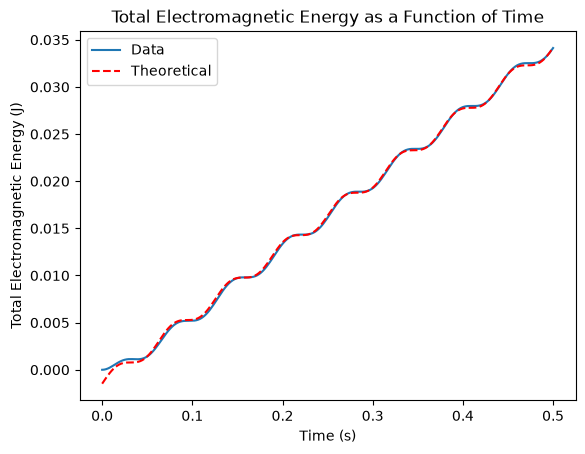

The average deviation between the Data and the Theoretical is 1.95e-12 J
The average deviation divided the average energy is 1.19e-10


In [3]:
#plot the total energy of the sim to make sure reflections are working correctly
#looks like sin(x) + x, which si awesome sauce
EE = np.sum(np.sum(sol.y.T.reshape(-1, 6, my, mx)[:, :3]**2, axis=1) * dx * dy, axis=(1, 2))
BB = np.sum(np.sum(sol.y.T.reshape(-1, 6, my, mx)[:, 3:6]**2, axis=1) * dx * dy, axis=(1, 2))
plt.plot(t_eval, 0.5 * (EE + BB), label = "Data")

def theoretical(t, A, B):
    return A * (t/2 + np.sin(100*t)/200) - B

popt, pcov = curve_fit(theoretical, t_eval, 0.5 * (EE + BB), p0 = [0.14, 0.001])

plt.plot(t_eval, theoretical(t_eval, *popt), "r--", label = "Theoretical")

plt.xlabel('Time (s)')
plt.ylabel('Total Electromagnetic Energy (J)')
plt.title('Total Electromagnetic Energy as a Function of Time')
plt.legend()
plt.show()

print("The average deviation between the Data and the Theoretical is", np.round(np.sum(0.5 * (EE + BB) - theoretical(t_eval, *popt)) / len(t_eval), 14), "J")
print("The average deviation divided the average energy is", np.round(np.sum(0.5 * (EE + BB) - theoretical(t_eval, *popt)) / len(t_eval)/np.mean(0.5 * (EE + BB)), 12))

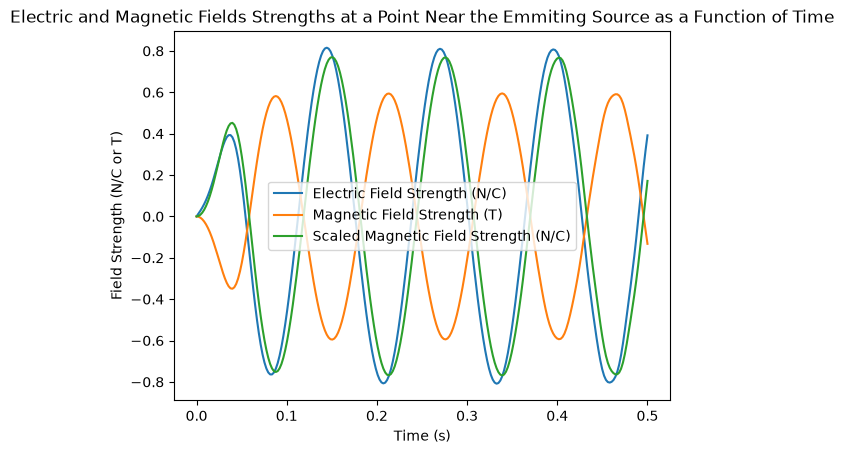

The average deviation between the Electric Field Strength and the Scaled Magnetic Field Strength is 0.00205 N/C
The average deviation divided the root mean square of the electric field is 0.00356


In [4]:
# check that E and B are porportional everywhere

E = (np.sum(sol.y.T.reshape(-1, 6, my, mx)[:, :3], axis=1))
B = (np.sum(sol.y.T.reshape(-1, 6, my, mx)[:, 4:6], axis=1))
plt.plot(t_eval, E[:, ny//2 + 5, ny//2 + 5], label = "Electric Field Strength (N/C)")
plt.plot(t_eval, B[:, ny//2 + 5, ny//2 + 5], label = "Magnetic Field Strength (T)") 

def scaledB(t, A):
    return A * B[:, ny//2 + 5, ny//2 + 5]

popt, pcov = curve_fit(scaledB, t_eval, E[:, ny//2 + 5, ny//2 + 5], p0 = [1], maxfev=50000)

plt.plot(t_eval, scaledB(t_eval, *popt), label = "Scaled Magnetic Field Strength (N/C)") 

plt.xlabel('Time (s)')
plt.ylabel('Field Strength (N/C or T)')
plt.title('Electric and Magnetic Fields Strengths at a Point Near the Emmiting Source as a Function of Time')
plt.legend()
plt.show()

print("The average deviation between the Electric Field Strength and the Scaled Magnetic Field Strength is", np.round(np.sum(E[:, ny//2 + 5, ny//2 + 5] - scaledB(t_eval, *popt)) / len(t_eval), 5), "N/C")
print("The average deviation divided the root mean square of the electric field is", np.round(np.sum(E[:, ny//2 + 5, ny//2 + 5] - scaledB(t_eval, *popt)) / len(t_eval) / (1/np.sqrt(2) * np.max(E[:, ny//2 + 5, ny//2 + 5])), 5))

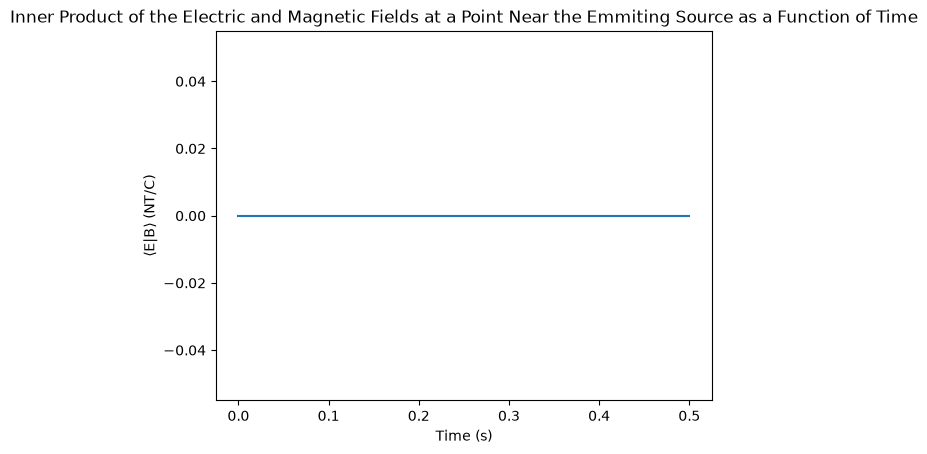

The average deviation between the ⟨E|B⟩ and 0 is 0.0 (NT/C)


In [5]:
# check that E and B are othogonal everwhere

E = sol.y.T.reshape(-1, 6, my, mx)[:, :3]
B = sol.y.T.reshape(-1, 6, my, mx)[:, 3:6]
plt.plot(t_eval, np.sum(E * B, axis=1)[:, ny//2 + 5, ny//2 + 5])

plt.xlabel('Time (s)')
plt.ylabel('⟨E|B⟩ (NT/C)')
plt.title('Inner Product of the Electric and Magnetic Fields at a Point Near the Emmiting Source as a Function of Time')
plt.show()

print("The average deviation between the ⟨E|B⟩ and 0 is", np.sum(np.sum(E * B, axis=1)[:, ny//2 + 5, ny//2 + 5]) / len(t_eval), "(NT/C)")

1.0612030685240983 +/- 0.0037488441194610178


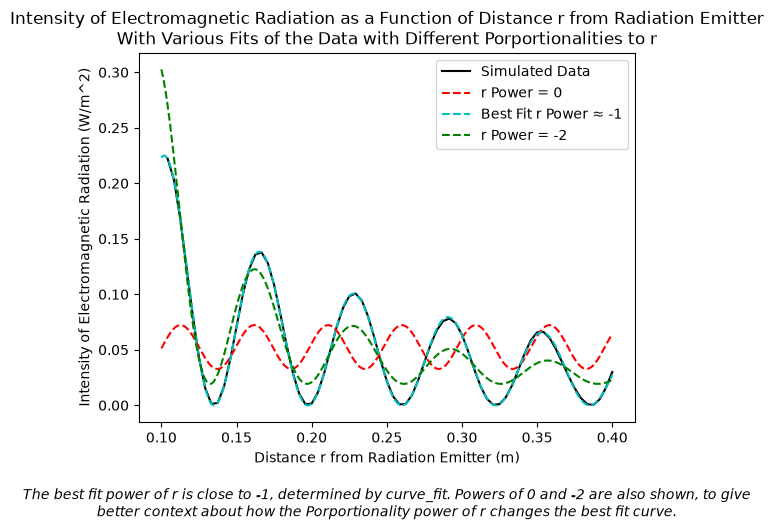

In [6]:
#plot the amplitude of the em wave distance r from the pulse

startX, endX = 0.6, 0.9
startFit = np.round(startX / dx).astype(int)
endFit = np.round(endX / dx).astype(int)
rOffset = 0.5

U = sol.y.T.reshape(-1, 6, my, mx)

ESlice = U[:, :3, ny//2 + 1, startFit:endFit]
BSlice = U[:, 3:6, ny//2 + 1, startFit:endFit]

intensity = np.linalg.norm(np.cross(ESlice, BSlice, axis=1), axis=1) / mu

plt.plot(x[startFit + 1: endFit + 1] - rOffset, intensity[223], "k-" , label = "Simulated Data")

def sincVariableRPower(r, A, B, C, D, E):
    return A * np.sinc((B * (r - C)) / np.pi)**2 * B * np.abs(r - C) ** E + D
def sinc0(r, A, B, C, D):
    return A * np.sinc((B * (r - C)) / np.pi)**2 * B * np.abs(r - C) ** 2 + D
def sinc1(r, A, B, C, D):
    return A * np.sinc((B * (r - C)) / np.pi)**2 * B * np.abs(r - C) + D
def sinc2(r, A, B, C, D):
    return A * np.sinc((B * (r - C)) / np.pi)**2 * B + D

lin = np.linspace(startX - rOffset, endX - rOffset, 1000)

popt, pcov = curve_fit(sincVariableRPower, x[startFit + 1: endFit + 1] - rOffset, intensity[223], p0 = [0.9, 48, 0, 0, 1], maxfev=50000)
popt0, pcov0 = curve_fit(sinc0, x[startFit + 1: endFit + 1] - rOffset, intensity[223], p0 = [0.9, 48, 0, 0], maxfev=50000)
popt1, pcov1 = curve_fit(sinc1, x[startFit + 1: endFit + 1] - rOffset, intensity[223], p0 = [0.9, 48, 0, 0], maxfev=50000)
popt2, pcov2 = curve_fit(sinc2, x[startFit + 1: endFit + 1] - rOffset, intensity[223], p0 = [0.9, 48, 0, 0], maxfev=50000)

plt.plot(lin, sinc0(lin, *popt0), "r--", label = "r Power = 0")
#plt.plot(lin, sinc1(lin, *popt1), "k--", label = "r Power = -1")
plt.plot(lin, sincVariableRPower(lin, *popt), "c--", label = "Best Fit r Power ≈ -1")
plt.plot(lin, sinc2(lin, *popt2), "g--", label = "r Power = -2")

print(popt[4],"+/-",  np.sqrt(pcov[4, 4]))

plt.xlabel('Distance r from Radiation Emitter (m)')
plt.ylabel('Intensity of Electromagnetic Radiation (W/m^2)')
plt.title('Intensity of Electromagnetic Radiation as a Function of Distance r from Radiation Emitter\nWith Various Fits of the Data with Different Porportionalities to r')
plt.text(0.25, -0.1, "The best fit power of r is close to -1, determined by curve_fit. Powers of 0 and -2 are also shown, to give better context about how the Porportionality power of r changes the best fit curve.", ha="center", fontsize=10, style="italic", wrap=True)
plt.legend()
plt.show()

#fits sin(x)^2/x^2 * |x|, which is also expected